In [40]:
!pip install datasets

In [41]:
import torch

model = torch.hub.load(
    'facebookresearch/dino:main',
    'dino_resnet50',
    pretrained=True
)

model.load_state_dict(
    torch.load(
        "/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",
        map_location="cpu"
    )
)

model = model.cuda()
model.eval()

print("DINO loaded")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded


In [42]:
def forward_features(x):
    return model(x)

model.forward_features = forward_features

In [44]:
import sys

sys.path.append("/home/zahranadeem/AgriCLIP/AgriCLIP_alignment")

print("Path added")

Path added


In [45]:
from TextToConcept import TextToConcept

text_to_concept = TextToConcept(
    model,
    "Dino"
)

text_to_concept.load_linear_aligner(
    "/home/zahranadeem/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth"
)

print("AgriCLIP ready")
print(type(text_to_concept))

AgriCLIP ready
<class 'TextToConcept.TextToConcept'>


In [46]:
from datasets import load_dataset


dataset = load_dataset("BrandonFors/Plant-Diseases-PlantVillage-Dataset")

# View the full features (image, label, leaf_id, crop, disease)
print(dataset)

# Inspect a single sample's meta dictionary
print(dataset["train"][0])



DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 43456
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10849
    })
})
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x7D8D755D0BE0>, 'label': 0}


In [47]:
print(dataset["train"].features)

sample = dataset["train"][0]

print(sample.keys())

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', '

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x7D8E510EF4F0>, 'label': 0}


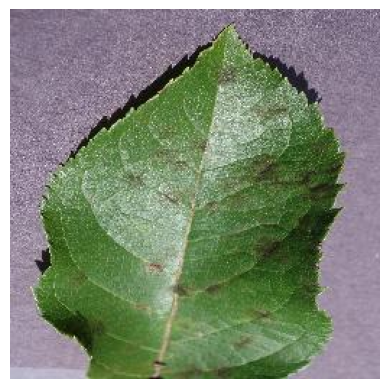

In [57]:
import matplotlib.pyplot as plt

sample = dataset["train"][70]

plt.imshow(sample["image"])
plt.axis("off")

print(sample)

In [58]:
class_names = dataset["train"].features["label"].names

print("Number of classes:", len(class_names))
print(class_names[:20])

Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy']


In [59]:

classifier = text_to_concept.get_zero_shot_classifier(
    class_names,
    prompts=["a photo of {}"]
)

In [60]:
import numpy as np
import torch

sample = dataset["train"][0]

image = sample["image"]

gt = class_names[sample["label"]]

img_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = classifier(img_tensor)

scores = logits.squeeze().cpu().numpy()

top5_idx = np.argsort(scores)[-5:][::-1]

print("Ground Truth:", gt)
print()

for rank, idx in enumerate(top5_idx, start=1):
    print(
        f"{rank}. {class_names[idx]} ({scores[idx]:.4f})"
    )

Ground Truth: Apple___Apple_scab

1. Peach___Bacterial_spot (0.3121)
2. Grape___Leaf_blight_(Isariopsis_Leaf_Spot) (0.3002)
3. Potato___Early_blight (0.2954)
4. Tomato___Bacterial_spot (0.2935)
5. Potato___Late_blight (0.2934)


In [61]:
import random
import numpy as np

random.seed(42)

test_indices = random.sample(
    range(len(dataset["train"])),
    50
)

top1 = 0
top5 = 0

for idx in test_indices:

    sample = dataset["train"][idx]

    image = sample["image"]

    gt = class_names[sample["label"]]

    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()

    top5_idx = np.argsort(scores)[-5:][::-1]

    pred1 = class_names[top5_idx[0]]

    top5_classes = [
        class_names[i]
        for i in top5_idx
    ]

    if pred1 == gt:
        top1 += 1

    if gt in top5_classes:
        top5 += 1

print("Top1 Accuracy:", top1/50)
print("Top5 Accuracy:", top5/50)

Top1 Accuracy: 0.04
Top5 Accuracy: 0.12
